In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
data = pd.read_csv("Salary_Data.csv")
df = pd.DataFrame(data)
df

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0
5,2.9,56642.0
6,3.0,60150.0
7,3.2,54445.0
8,3.2,64445.0
9,3.7,57189.0


In [3]:
df.shape

(30, 2)

In [4]:
df.head()

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


In [5]:
df.describe(include = "all")

,YearsExperience,Salary
count,30.000000,30.000000
mean,5.313333,76003.000000
std,2.837888,27414.429785
min,1.100000,37731.000000
25%,3.200000,56720.750000
50%,4.700000,65237.000000
75%,7.700000,100544.750000
max,10.500000,122391.000000


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     float64
dtypes: float64(2)
memory usage: 612.0 bytes


In [7]:
df.columns

Index(['YearsExperience', 'Salary'], dtype='str')

In [8]:
df.size

60

In [9]:
df.dtypes

YearsExperience    float64
Salary             float64
dtype: object

In [10]:
df.isna().sum()

YearsExperience    0
Salary             0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.corr()

,YearsExperience,Salary
YearsExperience,1.000000,0.978242
Salary,0.978242,1.000000


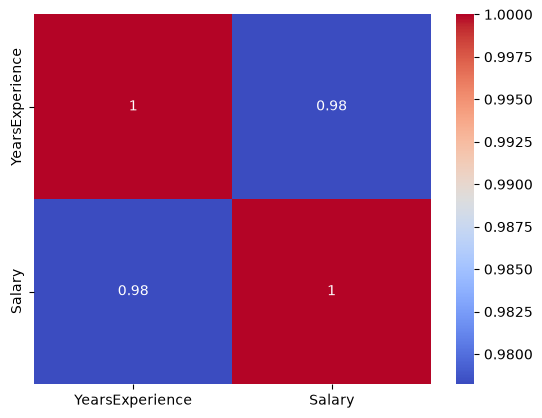

In [13]:
sns.heatmap(df.corr(),annot = True ,cmap = "coolwarm")
plt.show()

In [14]:
X = df.drop("Salary",axis= 1)
y = df["Salary"]



# X = df.iloc[:,:-1]
# y = df.iloc[:,1]

Text(0.5, 1.0, '')

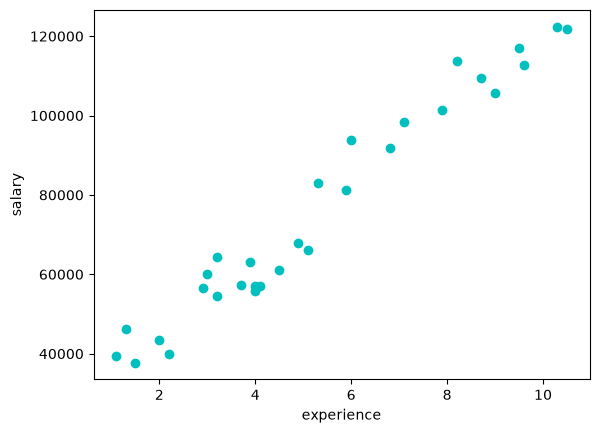

In [15]:
plt.scatter(X,y,color = 'c')
plt.xlabel("experience")
plt.ylabel("salary")
plt.title("")


In [16]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.3,random_state = 42)


In [17]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [18]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train,y_train)
y_pred = model.predict(X_test)
y_pred

array([115573.62288352,  71679.93878159, 102498.90847018,  75415.57147111,
        55803.4998511 ,  60473.04071301, 122110.98009019, 107168.44933209,
        63274.76523015])

In [19]:
print(model.predict(scaler.transform([[2.8]])))
# print(model.predict(scaler.transform([[7.3]])))

[52067.86716158]


C:\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


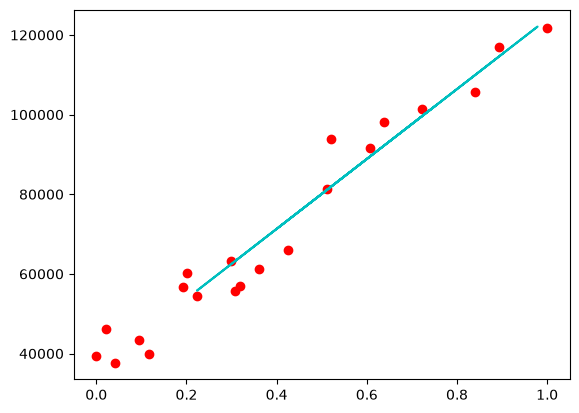

In [20]:
plt.scatter(X_train,y_train,color='r')
plt.plot(X_test,y_pred,color = 'c')


In [21]:
# slope
print(model.coef_)

[87787.36820386]


In [22]:
# to print the constant

print(model.intercept_)

36191.428231089914


In [23]:
# Data Frame
# Actual_value
# Predicted _ value
# difference



In [24]:
df_1 = pd.DataFrame({'Actual_value': y_test,'Predicted_value': y_pred,'difference':y_test - y_pred})
df_1 = df_1.reset_index(drop=True)
df_1


,Actual_value,Predicted_value,difference
0,112635.0,115573.622884,-2938.622884
1,67938.0,71679.938782,-3741.938782
2,113812.0,102498.908470,11313.091530
3,83088.0,75415.571471,7672.428529
4,64445.0,55803.499851,8641.500149
5,57189.0,60473.040713,-3284.040713
6,122391.0,122110.980090,280.019910
7,109431.0,107168.449332,2262.550668
8,56957.0,63274.765230,-6317.765230


In [25]:
from sklearn.metrics import mean_absolute_error
mae = mean_absolute_error(y_test,y_pred)
mae

5161.32871040018

In [26]:
from sklearn.metrics import mean_absolute_percentage_error
mape = mean_absolute_percentage_error(y_test,y_pred)
mape

0.06647907533756248

In [27]:
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(y_test,y_pred)
mse

37784662.46621313

In [28]:
from sklearn.metrics import root_mean_squared_error
rmse = root_mean_squared_error(y_test,y_pred)
rmse

6146.923007994579

In [29]:
from sklearn.metrics import r2_score
score = r2_score(y_test,y_pred)
score

0.9414466227178214

its best model beacuse r2 score is high and absolute percentage score is low